# Colab Intro

## Obliczenie sumy $n$ wyrazów ciągu geometrycznego

Ciąg geometryczny to ciąg liczbowy, w którym każdy kolejny wyraz powstaje pomnożeniem poprzedniego przez stałą iloraz $q$.

Wzór ogólny na sumę $n$ pierwszych wyrazów ciągu geometrycznego:

$$S_n = a_1 \frac{1 - q^n}{1 - q} \quad \text{dla } q \neq 1$$

Gdzie:
- $a_1$ — pierwszy wyraz ciągu,
- $q$ — iloraz ciągu,
- $n$ — liczba wyrazów.

In [ ]:
# 3. Liczenie 2 + 2
wynik_suma = 2 + 2
print("2 + 2 =", wynik_suma)

2 + 2 = 4


In [ ]:
# 4. Liczenie pi^pi
import math

wynik_pi = math.pi ** math.pi
print("pi^pi =", wynik_pi)

pi^pi = 36.4621596072079


In [ ]:
# 5. Suma kwadratów liczb od 1 do 100
suma_kwadratow = sum(i**2 for i in range(1, 101))
print("Suma kwadratów liczb od 1 do 100:", suma_kwadratow)

Suma kwadratów liczb od 1 do 100: 338350


In [ ]:
# 6. Zapis wyniku sumy kwadratów do pliku colab_wynik.txt
# Plik zostanie zapisany w głównym katalogu środowiska wykonawczego (runtime)
with open("colab_wynik.txt", "w", encoding="utf-8") as f:
    f.write(str(suma_kwadratow))

print("Plik colab_wynik.txt został pomyślnie zapisany.")

Plik colab_wynik.txt został pomyślnie zapisany.


<>:11: SyntaxWarning: invalid escape sequence '\i'
<>:11: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1726/848562209.py:11: SyntaxWarning: invalid escape sequence '\i'
  plt.title("Wykres $y = k^2$ dla $k \in [1, 20]$")


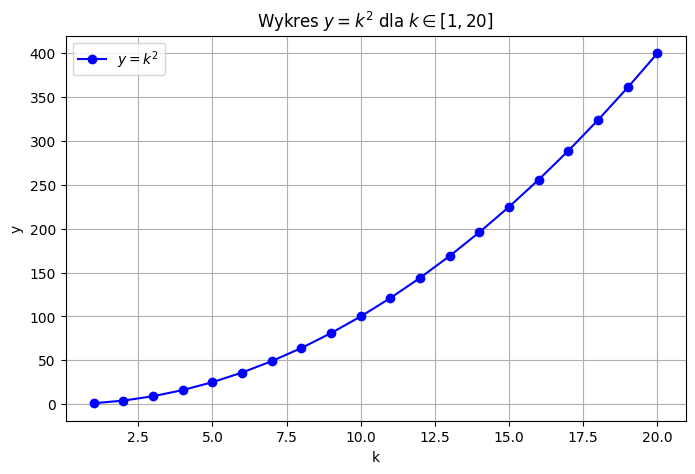

In [ ]:
# 7 i 8. Wykres y = k^2 dla k = 1,...,20 oraz zapis do pliku wykres.png
import matplotlib.pyplot as plt

k = list(range(1, 21))
y = [i**2 for i in k]

plt.figure(figsize=(8, 5))
plt.plot(k, y, marker="o", color="b", label="$y = k^2$")
plt.xlabel("k")
plt.ylabel("y")
plt.title("Wykres $y = k^2$ dla $k \in [1, 20]$")
plt.grid(True)
plt.legend()

# Zapis do pliku
plt.savefig("wykres.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# 9. Generowanie animacji wahadła matematycznego, osadzenie w notebooku i zapis do video.mp4
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# Parametry wahadła
g = 9.81
L = 1.0
dt = 0.05
t = np.arange(0, 5, dt)

# Kąt w czasie (dla małych drgań)
theta_0 = np.radians(30)
omega = np.sqrt(g / L)
theta = theta_0 * np.cos(omega * t)

# Pozycje (x, y)
x = L * np.sin(theta)
y = -L * np.cos(theta)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 0.2)
ax.set_aspect('equal')
ax.grid(True)

line, = ax.plot([], [], 'o-', lw=2, color='darkblue')
trace, = ax.plot([], [], '-', lw=1, color='gray', alpha=0.5)

def init():
    line.set_data([], [])
    trace.set_data([], [])
    return line, trace

def animate(i):
    line.set_data([0, x[i]], [0, y[i]])
    trace.set_data(x[:i], y[:i])
    return line, trace

ani = animation.FuncAnimation(fig, animate, init_func=init, frames=len(t), interval=50, blit=True)
plt.close(fig)

# Zapis do video.mp4 (używa ffmpeg dostępnego w Colabie)
ani.save("video.mp4", writer="ffmpeg", fps=20)

# Display video in notebook
HTML("""
<video width="400" height="400" controls autoplay loop>
  <source src="video.mp4" type="video/mp4">
</video>
""")

In [ ]:
# 10. Konwersja pliku video.mp4 do GIF (video.gif)
# Plik zostanie zapisany w głównym katalogu środowiska wykonawczego
import imageio

reader = imageio.get_reader("video.mp4")
fps = reader.get_meta_data()['fps']

writer = imageio.get_writer("video.gif", fps=fps)

for frame in reader:
    writer.append_data(frame)

writer.close()
print("Plik video.gif został pomyślnie wygenerowany!")

Plik video.gif został pomyślnie wygenerowany!


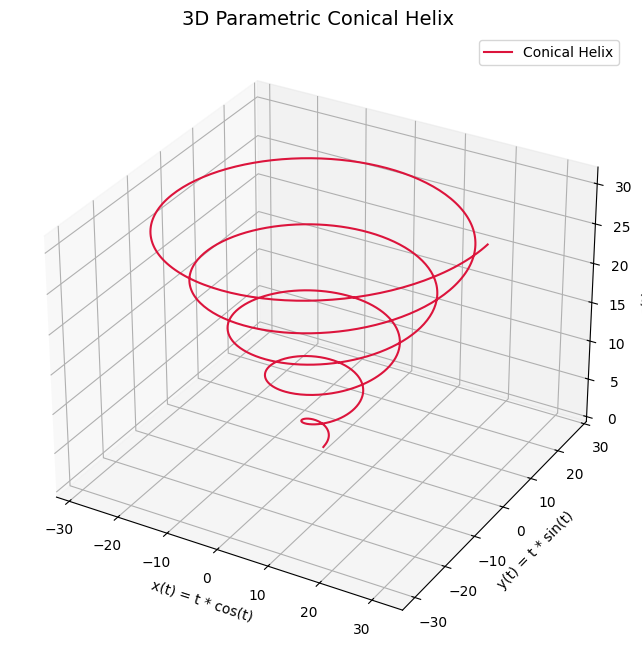

In [ ]:
# 11. Zmodyfikowana 3D krzywa parametryczna (Helisa stożkowa) i zapis do parametric_curve.png
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Zmodyfikowane równania parametryczne (helisa stożkowa / Conical Helix)
t = np.linspace(0, 10 * np.pi, 1000)
x = t * np.cos(t)
y = t * np.sin(t)
z = t

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Conical Helix", color="crimson", lw=1.5)
ax.set_title("3D Parametric Conical Helix", fontsize=14)
ax.set_xlabel("x(t) = t * cos(t)")
ax.set_ylabel("y(t) = t * sin(t)")
ax.set_zlabel("z(t) = t")
ax.legend()

# Zapis wykresu
plt.savefig("parametric_curve.png", dpi=150, bbox_inches="tight")
plt.show()